# IMED Experiment 6 | PBM boundary and mass diagnostics

Run the cells in order from the IMED workspace. This notebook uses the recorded Experiment 6 and fitted Model 2. Set `model_index = 0` to try Model 1. The PBM plots remain available if QMOM stops.

The API inventory includes solid mass transported beyond the size mesh. The accumulator records mass at crossing. The resolved size, number, and volume plots describe crystals still on the mesh. Aggregates whose birth sizes exceed the mesh are excluded from the finite-volume collision update. Closing the mass balance accounts for outflow and does not validate the resolved size distribution or crystal yield.


In [1]:
from pathlib import Path
import sys

# Locate the IMED package when the kernel starts in notebooks/ or the workspace root.
cwd = Path.cwd().resolve()
root = next((folder for folder in (cwd, *cwd.parents)
             if (folder / "imed_python" / "solver.py").is_file()), None)
if root is None:
    raise RuntimeError("Open this notebook from the IMED workspace or its notebooks folder.")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

from imed_python.distribution import cell_volumes, volume_distribution
from imed_python.solver import simulate
from imed_python.validation.qmom import solve_ccas_qmom

plt.rcParams.update({
    "figure.dpi": 125, "axes.grid": True, "grid.alpha": 0.26,
    "axes.spines.top": False, "axes.spines.right": False,
})

In [2]:
from imed_python.solver import read_model, model_parameters

path = (
    "C:/Users/abotondo/OneDrive - purdue.edu/Pfizer/2. Purdue Experiments/"
    "Evaluated expts/IMED_files/MD_refit_ACTUAL_D_values_20261008.mat"
)

case = read_model(path)
experiment_index = 5  # Experiment 6
model_index = 1       # Model 2. Use 0 for Model 1.

experiment = case["ExpData"][experiment_index]
process = case["ProcInf"][experiment_index]
solubility = case["Solubility"]
settings = dict(case["pbmsetting"])
parameters = model_parameters(case["ModelParameter"][model_index])

shape_factor = process["ShapeFactor"]
solid_density_g_cm3 = process["SolidDensity"]

In [3]:
count, concentration, csd, state = simulate(parameters, experiment, process, solubility, settings,
                                return_history=True)
time = count[0]
qmom = None
try:
    qmom = solve_ccas_qmom(parameters, experiment, process, solubility, settings, time=time)
except (ValueError, RuntimeError, TimeoutError) as error:
    print(f"QMOM stopped: {error}")
    print("Plotting the completed PBM calculation.")

bins = settings["N"]
edges = np.linspace(settings["Lmin"], settings["Lmax"], bins + 1)
number_per_bin = state[:bins] * np.diff(edges)[:, None]
pbm_number = number_per_bin.sum(axis=0)
pbm_volume = cell_volumes(edges, shape_factor) @ number_per_bin / 1e12  # cm³
pbm_mean = np.divide(csd[0] @ number_per_bin, pbm_number,
                     out=np.full_like(pbm_number, np.nan), where=pbm_number > 0)

pbm_crystal = solid_density_g_cm3 * pbm_volume
pbm_dissolved = state[bins] * state[bins + 1]
pbm_resolved_total = pbm_crystal + pbm_dissolved
escaped = state[bins + 5]
pbm_total = pbm_resolved_total + escaped
inventory_error = np.max(np.abs(pbm_total - pbm_total[0]))
hours = time / 3600
print(f"PBM final concentration: {concentration[1, -1]:.6g} g/g solution")
print(f"Measured final concentration: {experiment['ConcentrationData'][1, -1]:.6g} g/g solution")
print(f"PBM final crystal mass inside mesh: {pbm_crystal[-1]:.4g} g")
print(f"Crystal mass transported beyond Lmax: {escaped[-1]:.4g} g")
print(f"Initial API inventory: {pbm_total[0]:.4g} g")
print(f"Max inventory residual with boundary flux: {inventory_error:.3g} g")
if qmom is not None:
    qmom_total = qmom.crystal_mass + qmom.dissolved_mass


QMOM stopped: QMOM upper size boundary at t=3262.32 s: trial node 250.1 µm exceeds Lmax=250 µm and represents 95.38% of quadrature crystal volume.
Plotting the completed PBM calculation.
PBM final concentration: 0.00292652 g/g solution
Measured final concentration: 0.00233476 g/g solution
PBM final crystal mass inside mesh: 8.703 g
Crystal mass transported beyond Lmax: 11.86 g
Initial API inventory: 21.78 g
Max inventory residual with boundary flux: 2.64e-06 g


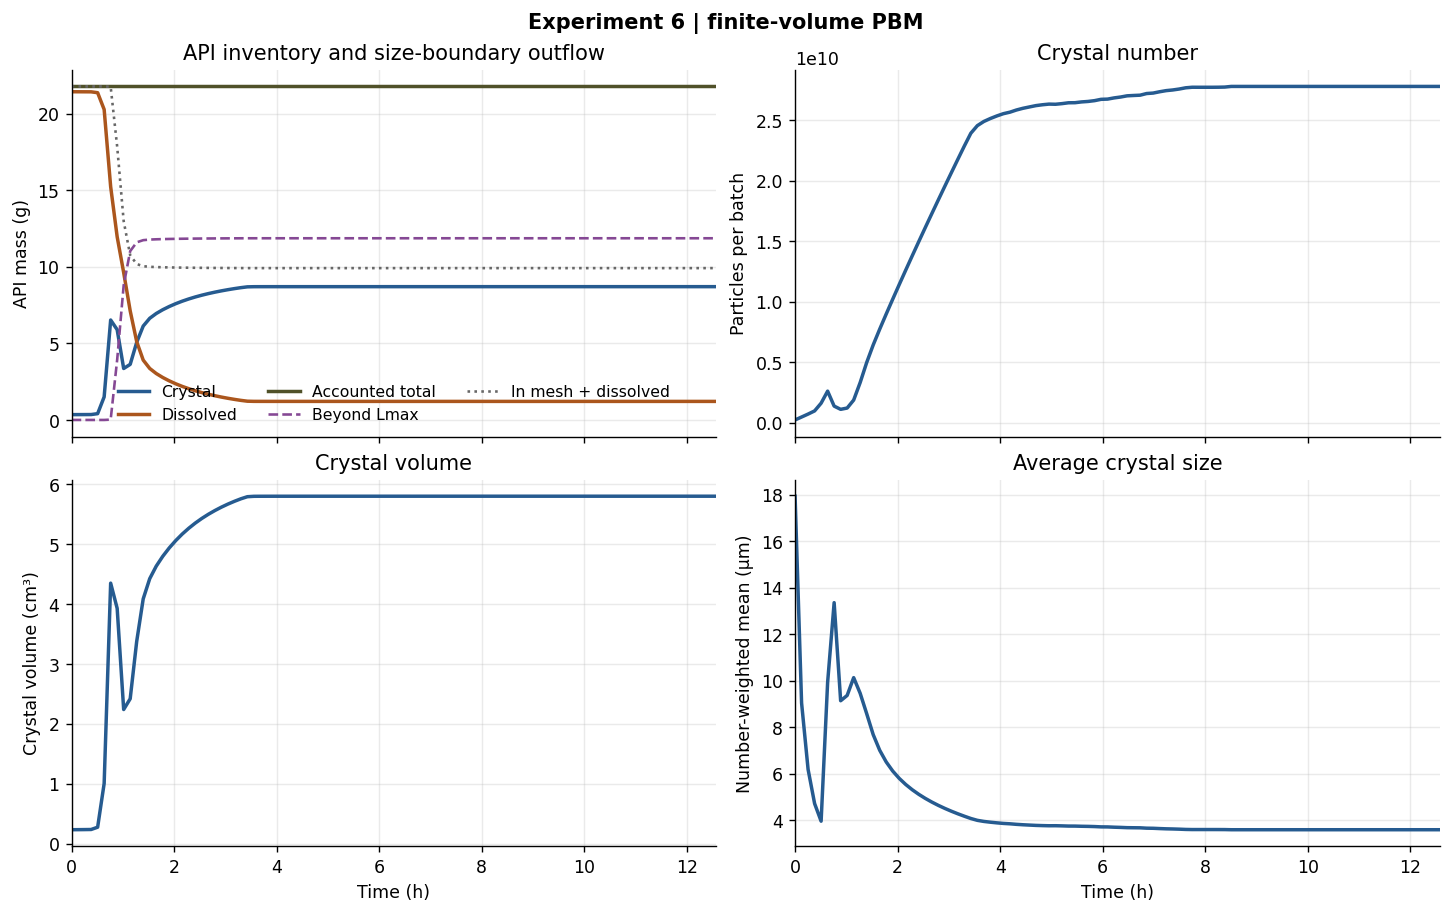

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(11.5, 7.2), sharex=True, layout="constrained")
fig.suptitle("Experiment 6 | " + ("PBM and QMOM" if qmom is not None else "finite-volume PBM"),
             fontweight="bold")
palette = {"Crystal": "#265b90", "Dissolved": "#ab561d", "Accounted total": "#505129"}

def paired(ax, pbm, reference, color, label=None):
    ax.plot(hours, pbm, color=color, lw=2.0, label=label)
    if reference is None:
        return
    ax.plot(hours, reference, color=color, marker="o", markersize=4,
            markevery=8, markerfacecolor="white", markeredgewidth=1.1, lw=0)

for label, pbm, reference in [
    ("Crystal", pbm_crystal, (qmom.crystal_mass if qmom is not None else None)),
    ("Dissolved", pbm_dissolved, (qmom.dissolved_mass if qmom is not None else None)),
    ("Accounted total", pbm_total, (qmom_total if qmom is not None else None)),
]:
    paired(axes[0, 0], pbm, reference, palette[label], label)
axes[0, 0].plot(hours, escaped, color="#854894", ls="--", label="Beyond Lmax")
axes[0, 0].plot(hours, pbm_resolved_total, color="#676767", ls=":", label="In mesh + dissolved")
axes[0, 0].set(title="API inventory and size-boundary outflow", ylabel="API mass (g)")
axes[0, 0].legend(frameon=False, ncol=3, fontsize=9)

panels = [
    (axes[0, 1], pbm_number, (qmom.number if qmom is not None else None), "Crystal number", "Particles per batch"),
    (axes[1, 0], pbm_volume, (qmom.volume / 1e12 if qmom is not None else None), "Crystal volume", "Crystal volume (cm³)"),
    (axes[1, 1], pbm_mean, (qmom.mean_size if qmom is not None else None), "Average crystal size", "Number-weighted mean (µm)"),
    
]
for ax, pbm, reference, title, unit in panels:
    paired(ax, pbm, reference, palette["Crystal"])
    ax.set(title=title, ylabel=unit)
if qmom is not None:
    axes[0, 1].legend(handles=[
        Line2D([], [], color=palette["Crystal"], lw=2, label="IMED PBM"),
        Line2D([], [], color=palette["Crystal"], marker="o", markerfacecolor="white",
               lw=0, label="QMOM"),
    ], frameon=False)
for ax in axes[-1]:
    ax.set_xlabel("Time (h)")
axes[0, 0].set_xlim(hours[0], hours[-1])
plt.show()

## Operating conditions

The system volume combines the additive solvent and antisolvent volumes and resolved crystal volume. It excludes dissolved API partial volume and unresolved crystals. Equilibrium concentration uses the full MAT solubility model and the simulated antisolvent mass fraction.

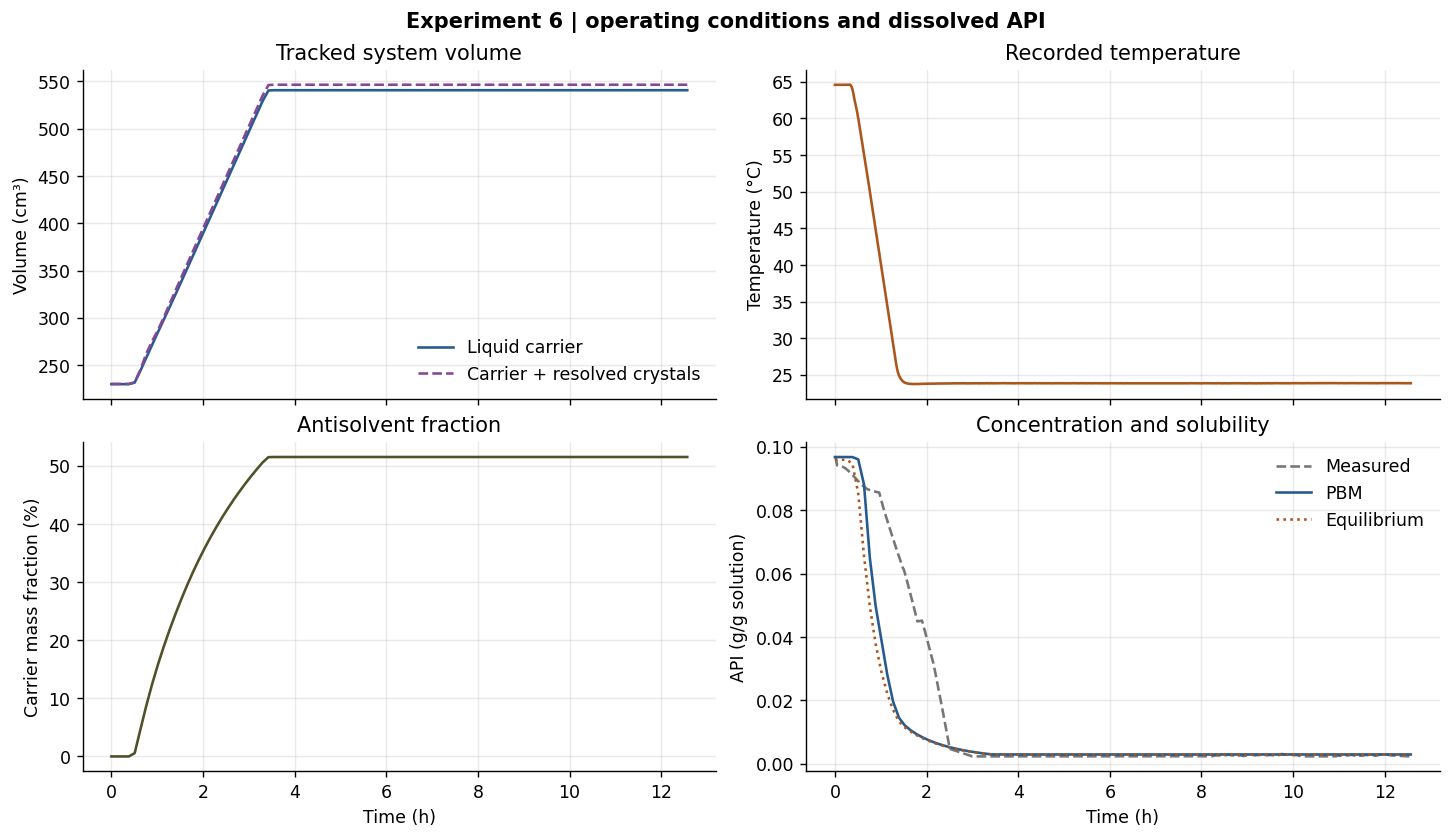

In [5]:
solvent = state[bins + 2]
anti = 1 - solvent
liquid_volume = state[bins + 1] * (solvent / process["SolventDensity"]
                                   + anti / process["AntiSolventDensity"])
recorded_temp = np.asarray(experiment["TemperatureData"])
temp_k = np.interp(time, *recorded_temp) + 273.15
a, b, c, d, e, f, g, h = (solubility[key] for key in "abcdefgh")
csat = np.exp(a + b / temp_k + c * np.log(temp_k) + d * anti + e * np.exp(anti)
              + f * anti**2 + g * anti / temp_k + h * np.exp(anti) / temp_k)

fig, axes = plt.subplots(2, 2, figsize=(11.5, 6.6), sharex=True, layout="constrained")
fig.suptitle("Experiment 6 | operating conditions and dissolved API", fontweight="bold")
axes[0, 0].plot(hours, liquid_volume, color="#265b90", label="Liquid carrier")
axes[0, 0].plot(hours, liquid_volume + pbm_volume, color="#854894", ls="--",
                label="Carrier + resolved crystals")
axes[0, 0].set(title="Tracked system volume", ylabel="Volume (cm³)")
axes[0, 0].legend(frameon=False)
axes[0, 1].plot(recorded_temp[0] / 3600, recorded_temp[1], color="#ab561d")
axes[0, 1].set(title="Recorded temperature", ylabel="Temperature (°C)")
axes[1, 0].plot(hours, 100 * anti, color="#505129")
axes[1, 0].set(title="Antisolvent fraction", ylabel="Carrier mass fraction (%)")
measured = experiment["ConcentrationData"]
axes[1, 1].plot(measured[0] / 3600, measured[1], color="#767676", ls="--", label="Measured")
axes[1, 1].plot(hours, concentration[1], color="#265b90", label="PBM")
axes[1, 1].plot(hours, csat, color="#ab561d", ls=":", label="Equilibrium")
axes[1, 1].set(title="Concentration and solubility", ylabel="API (g/g solution)")
axes[1, 1].legend(frameon=False)
for ax in axes[-1]:
    ax.set_xlabel("Time (h)")
plt.show()

## Resolved volume-weighted size

Open circles show the supplied seed and final measured percentiles. The MAT case contains no measured percentile trajectories or final measured full distribution. Each simulated distribution snapshot integrates to 100% of resolved crystal volume.

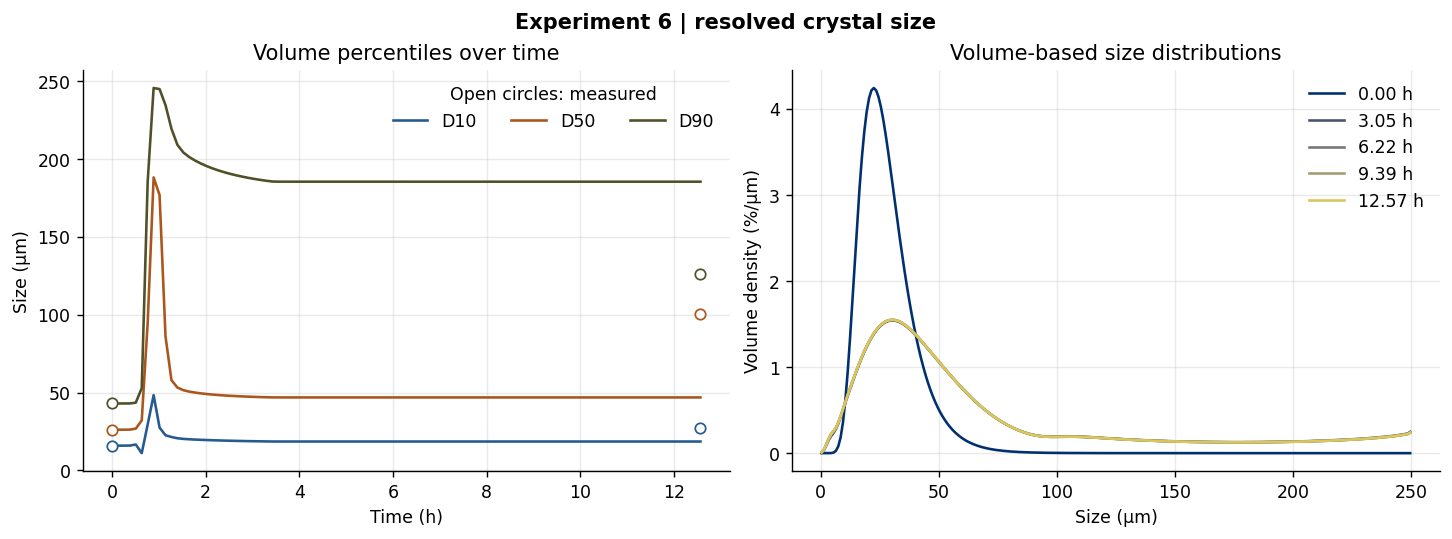

In [6]:
distributions = []
percentiles = np.full((3, time.size), np.nan)
for i, density in enumerate(state[:bins].T):
    curve, sizes = volume_distribution(np.vstack((csd[0], density)), process, settings)
    distributions.append(curve)
    if sizes is not None:
        percentiles[:, i] = sizes

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), layout="constrained")
fig.suptitle("Experiment 6 | resolved crystal size", fontweight="bold")
for i, (name, color) in enumerate(zip(("D10", "D50", "D90"), ("#265b90", "#ab561d", "#505129"))):
    axes[0].plot(hours, percentiles[i], color=color, label=name)
    for field, at in (("InitialD10D50D90", hours[0]), ("FinalD10D50D90", hours[-1])):
        values = np.asarray(experiment.get(field, []))
        if values.size == 3:
            axes[0].scatter(at, values[i], edgecolors=color, facecolors="white", zorder=5)
axes[0].set(title="Volume percentiles over time", xlabel="Time (h)", ylabel="Size (µm)")
axes[0].legend(frameon=False, ncol=3, title="Open circles: measured")
snapshots = np.linspace(0, time.size - 1, 5, dtype=int)
for i, color in zip(snapshots, plt.cm.cividis(np.linspace(0.08, 0.86, len(snapshots)))):
    axes[1].plot(*distributions[i], color=color, label=f"{hours[i]:.2f} h")
axes[1].set(title="Volume-based size distributions", xlabel="Size (µm)", ylabel="Volume density (%/µm)")
axes[1].legend(frameon=False)
plt.show()